# Supplementary Material — Part I: the data behind the paper (S1–S7)

Companion to `paper_main_figures.ipynb`. This notebook documents the **inputs**: the climate ensemble,
the balancing zones, the bias-corrected climate variables, the derived capacity factors, the hydro
fields, and the TYNDP-2024 scenario. It does **not** touch the extremes pipeline — the method defence
and the event results live in `paper_si_results.ipynb` (S8–S21).

It loads only small precomputed `.nc` files, so it runs in seconds.

| # | Figure |
|---|---|
| **S1** | The 9 GCM–RCM chains and their 20-year warming-level windows |
| **S2** | The six TYNDP balancing zones (map) |
| **S3** | Bias-corrected climate variables across warming levels — annual |
| **S4** | Same — by season |
| **S5** | PV and wind capacity factors across warming levels |
| **S6** | Hydro: run-of-river, reservoir inflow, reservoir dispatch |
| **S7** | The TYNDP-2024 scenario inputs |

The gridded GWL means come from `scripts/compute_climate_means_gwl.py` (a batch job — the
bias-corrected store is ~53 TB, so the reduction cannot live in a notebook).

*Hatching = fewer than 2/3 of the chains agree on the sign of the change — the same convention as the
main text.*


## 0 · Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy.conversion_energy.tyndp import (
    REALTIME_BALANCING_ZONES,
    load_tyndp_battery_capacities,
    load_tyndp_supply_capacities,
)
from cordex2energy_analysis.extremes_analysis import (
    compute_c2e_gwl_field,
    compute_country_gwl_field,
    mask_structural_zeros,
    resolve_gwl_period_definitions,
)
from cordex2energy_analysis.plotting_paper import (
    RIVER_CMAP,
    PaperStyle,
    load_country_geometry,
    plot_country_choropleth,
)
from cordex2energy_analysis.plotting_si import (
    plot_climate_gwl_maps,
    plot_country_gwl_maps,
    plot_gwl_windows,
    plot_tyndp_baseload,
    plot_tyndp_capacity,
    plot_zone_map,
)

sns.set_style("whitegrid", {"grid.color": ".93"})
plt.rcParams["hatch.linewidth"] = 0.6
plt.rcParams["figure.dpi"] = 110

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/c2e-analysis/share/proj failed


In [3]:
# ── Configuration — mirrors paper_main_figures.ipynb; the two must not drift apart ──────
paths = json.load(open("../paths.json"))
PATH_PROCESSED = Path(paths["path_data_processed"])
PATH_EXTREMES = PATH_PROCESSED / "extremes"
PATH_GWL = PATH_PROCESSED / "energy" / "analysis"
FIGS = Path(paths.get("path_figs", "../figs")) / "paper_si"
FIGS.mkdir(parents=True, exist_ok=True)

CLIMATE_SCENARIO = "rcp85"
RUN_TAG = "DE_2050_LOW_2050_reservoirdispatch_batteries_prosumer_sysflex_SWT120_3600"
WARMING_LEVELS = [1.5, 2.0, 3.0]          # +1.5 °C is the reference
ROBUSTNESS_FRACTION = 2 / 3

# The TYNDP scenario the whole paper runs on.
SUPPLY_SCENARIO, SUPPLY_YEAR = "LOW", 2050
DEMAND_SCENARIO, DEMAND_YEAR = "DE", 2050

SEASON_ORDER = ["DJF", "MAM", "JJA", "SON"]
ZONE_ORDER = ["Iberian_Peninsula", "South_East", "Central_Western",
              "Central_Eastern", "Nordic", "British_Isles"]
ZONE_LABELS = {"Iberian_Peninsula": "Iberian Peninsula", "South_East": "South-East",
               "Central_Western": "Central-West", "Central_Eastern": "Central-East",
               "Nordic": "Nordic", "British_Isles": "British Isles"}
GWL_COLORS = ["#4A90E2", "#F5A623", "#D0021B"]

countries = load_country_geometry(
    PATH_PROCESSED / "maps" / "natural_earth" / "ne_50m_admin_0_countries.geojson")
print(f"Country geometry: {len(countries)} polygons in the map extent")

Country geometry: 62 polygons in the map extent


In [4]:
# ── The chains, their GWL windows, and the PaperStyle every figure is drawn with ────────
models = sorted(
    "_".join(p.name.split("_")[:-1])
    for p in (PATH_EXTREMES / "residual_load").glob(f"*_{CLIMATE_SCENARIO}")
    if (p / RUN_TAG).exists()
)

period_defs, _, _ = resolve_gwl_period_definitions(
    warming_levels=WARMING_LEVELS,
    models=models,
    chain_meta_path="../models.json",
    gwl_yaml_path=PATH_PROCESSED / "cmip5_warming_levels_all_ens_1861_1900.yml",
    climate_scenario=CLIMATE_SCENARIO,
)
period_names = list(period_defs.keys())
REFERENCE, WARMEST = period_names[0], period_names[-1]
ROBUSTNESS_THRESHOLD = int(np.ceil(len(models) * ROBUSTNESS_FRACTION))

STYLE = PaperStyle(
    zones=ZONE_ORDER,
    zone_labels=ZONE_LABELS,
    period_names=period_names,
    gwl_colors=dict(zip(period_names, GWL_COLORS)),
    driver_palette={},                 # unused in this notebook: no attribution figures here
    duration_palette={},
    season_order=SEASON_ORDER,
    n_models=len(models),
    robustness_threshold=ROBUSTNESS_THRESHOLD,
    spread="minmax",
)
print(f"{len(models)} chains | robustness: {ROBUSTNESS_THRESHOLD}/{len(models)} must agree on the sign")
for period, windows in period_defs.items():
    print(f"  {period}: {len(windows)}/{len(models)} chains")

9 chains | robustness: 6/9 must agree on the sign
  +1.5°C: 9/9 chains
  +2.0°C: 9/9 chains
  +3.0°C: 9/9 chains


## S1 · The ensemble and its warming-level windows

Nine GCM–RCM chains: 2 RCMs × 5 driving GCMs, minus ALADIN63 × EC-EARTH, which does not exist. Each
chain reaches a given warming level in its **own** 20-year window, set by its driving GCM — so chains
that share a GCM share their windows, and the ensemble is not nine independent samples. The figure
shows that dependence rather than hiding it behind a single ensemble-mean window.

In [5]:
# The chain table: which GCM drives which RCM, and when each reaches every warming level.
rows = []
for model in models:
    rcm, gcm = model.split("_")[0], "_".join(model.split("_")[1:])
    row = {"RCM": rcm, "driving GCM": gcm}
    for period in period_names:
        window = period_defs[period].get(model)
        row[period] = f"{window[0]}–{window[1]}" if window else "—"
    rows.append(row)
chain_table = pd.DataFrame(rows).sort_values(["RCM", "driving GCM"]).reset_index(drop=True)
display(chain_table)

,RCM,driving GCM,+1.5°C,+2.0°C,+3.0°C
0,CNRM-ALADIN63,CNRM-CERFACS-CNRM-CM5_r1i1p1,2022–2041,2036–2055,2059–2078
1,CNRM-ALADIN63,MOHC-HadGEM2-ES_r1i1p1,2015–2034,2027–2046,2046–2065
2,CNRM-ALADIN63,MPI-M-MPI-ESM-LR_r1i1p1,2007–2026,2026–2045,2051–2070
3,CNRM-ALADIN63,NCC-NorESM1-M_r1i1p1,2024–2043,2040–2059,2064–2083
4,MOHC-HadREM3-GA7-05,CNRM-CERFACS-CNRM-CM5_r1i1p1,2022–2041,2036–2055,2059–2078
5,MOHC-HadREM3-GA7-05,ICHEC-EC-EARTH_r12i1p1,2009–2028,2026–2045,2052–2071
6,MOHC-HadREM3-GA7-05,MOHC-HadGEM2-ES_r1i1p1,2015–2034,2027–2046,2046–2065
7,MOHC-HadREM3-GA7-05,MPI-M-MPI-ESM-LR_r1i1p1,2007–2026,2026–2045,2051–2070
8,MOHC-HadREM3-GA7-05,NCC-NorESM1-M_r1i1p1,2024–2043,2040–2059,2064–2083


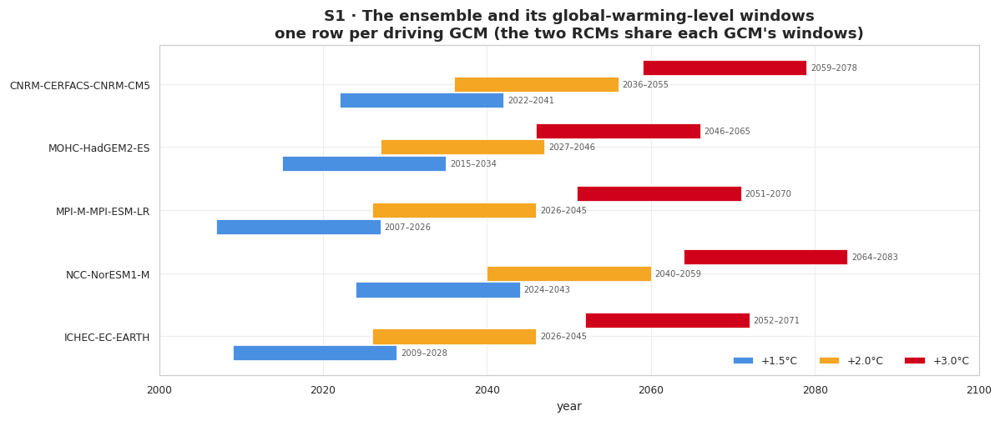

In [6]:
# One row per driving GCM: the two RCMs share each GCM's windows, so the 9-chain view is exact
# duplication. The RCM×GCM structure lives in the chain table above.
fig = plot_gwl_windows(period_defs, models, STYLE, group_by_gcm=True)
fig.savefig(FIGS / "S1_ensemble_gwl_windows.png", dpi=300, bbox_inches="tight")

## S2 · The six TYNDP balancing zones

Events are detected per zone, not per country: a deficit is a *system* state, and the balancing zone
is the level at which the TYNDP scenario clears. Countries inside the map extent that belong to no
zone are greyed — "not modelled" must be distinguishable from "modelled and unremarkable".

  Iberian Peninsula  (2): ES, PT
  South-East         (11): IT, GR, SI, HR, BA, RS, ME, MK, AL, MT, CY
  Central-West       (7): FR, DE, LU, BE, NL, CH, AT
  Central-East       (9): PL, CZ, SK, HU, RO, BG, EE, LV, LT
  Nordic             (4): NO, SE, FI, DK
  British Isles      (2): UK, IE


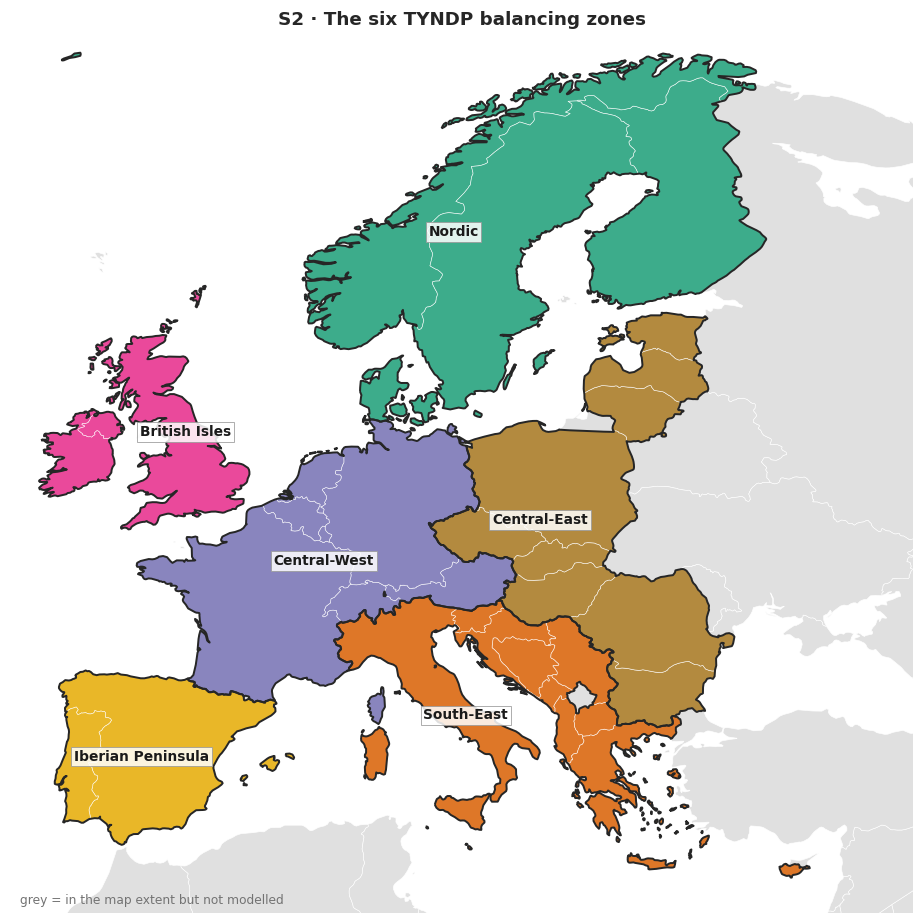

In [7]:
fig = plot_zone_map(REALTIME_BALANCING_ZONES, countries, STYLE)
fig.savefig(FIGS / "S2_balancing_zones.png", dpi=300, bbox_inches="tight")

for zone in ZONE_ORDER:
    members = REALTIME_BALANCING_ZONES[zone]
    print(f"  {ZONE_LABELS[zone]:<18} ({len(members)}): {', '.join(members)}")

## S3–S4 · The bias-corrected climate variables across warming levels

The five variables every conversion in the pipeline is built from. All are EQM bias-corrected against
CERRA (91-day window, 99 quantiles, trained 1991–2020).

The first column is the **absolute field at +1.5 °C** — without it a large percentage change cannot be
told from a large percentage change *on a negligible baseline*. The remaining columns are the change
relative to that reference. **`tas` is shown as an absolute change (K); the rest as a percentage** —
a percentage change in Kelvin is meaningless. That choice is not made here: it is read from the
`change_type` attribute written into each variable by `compute_climate_means_gwl.py`.

In [9]:
# The gridded GWL means (batch job: scripts/compute_climate_means_gwl.py). `Qrouted` is the
# bias-corrected runoff routed through the mRM model — the river-channel discharge that actually
# drives hydropower, distinct from the raw grid-cell runoff `mrro` above it.
CLIMATE_VARIABLES = ["tas", "rsds", "sfcWind", "pr", "mrro", "Qrouted"]

# The gridded files label seasons "Winter/Spring/Summer/Fall"; every table and figure in the paper
# uses the DJF/MAM/JJA/SON convention. Rename on load so the two can never be mixed up downstream.
GRID_SEASON_RENAME = {"Winter": "DJF", "Spring": "MAM", "Summer": "JJA", "Fall": "SON"}


def load_gwl_grids(kind: str, seasonal: bool = False) -> dict[str, xr.Dataset]:
    """One dataset per warming level.  `kind` is "climate" (S3/S4) or "" (the pv/wind file, S5).

    Fails loudly if the per-level files are inconsistent (different chains or grid) — which is what
    happens while `compute_climate_means_gwl.py` is mid-run and has only rewritten some of them.
    """
    folder = PATH_GWL / ("seasonal" if seasonal else "annual") / "gwl"
    suffix = {("climate", False): "_climate", ("climate", True): "_climate_meteorological",
              ("", False): "", ("", True): "_meteorological"}[(kind, seasonal)]

    grids = {}
    for warming_level, period in zip(WARMING_LEVELS, period_names):
        dataset = xr.open_dataset(folder / f"mean_gwl_{int(round(warming_level * 10))}{suffix}.nc")
        if seasonal:
            dataset = dataset.assign_coords(
                season=[GRID_SEASON_RENAME[str(s)] for s in dataset["season"].values]
            ).sel(season=SEASON_ORDER)
        grids[period] = dataset

    shapes = {p: (ds.sizes.get("model"), ds.sizes["lat"], ds.sizes["lon"]) for p, ds in grids.items()}
    if len(set(shapes.values())) > 1:
        raise RuntimeError(
            f"GWL {kind or 'energy'} files disagree on (model, lat, lon): {shapes}. "
            "compute_climate_means_gwl.py is probably still writing them — wait for it to finish.")
    return grids


climate_annual = load_gwl_grids("climate")
# Keep only variables present in EVERY warming level — so a mid-run state (Qrouted written for some
# levels but not others) drops Qrouted cleanly instead of crashing the plot on a missing variable.
CLIMATE_VARIABLES = [v for v in CLIMATE_VARIABLES
                     if all(v in climate_annual[p].data_vars for p in period_names)]
for period, ds in climate_annual.items():
    print(f"{period}: {dict(ds.sizes)}  {list(ds.data_vars)}")
print("plotting:", CLIMATE_VARIABLES)

+1.5°C: {'model': 9, 'lat': 426, 'lon': 510}  ['tas', 'rsds', 'sfcWind', 'pr', 'mrro', 'Qrouted']
+2.0°C: {'model': 9, 'lat': 426, 'lon': 510}  ['tas', 'rsds', 'sfcWind', 'pr', 'mrro']
+3.0°C: {'model': 9, 'lat': 426, 'lon': 510}  ['tas', 'rsds', 'sfcWind', 'pr', 'mrro']
plotting: ['tas', 'rsds', 'sfcWind', 'pr', 'mrro']


In [ ]:
fig = plot_climate_gwl_maps(climate_annual, CLIMATE_VARIABLES, countries, STYLE,
                            title="S3 · Bias-corrected EURO-CORDEX climate variables — annual mean")
fig.savefig(FIGS / "S3_climate_gwl_annual.png", dpi=200, bbox_inches="tight")

In [ ]:
climate_seasonal = load_gwl_grids("climate", seasonal=True)
# Filter against the SEASONAL files too — annual and seasonal are written by separate runs, so during
# a recompute one may carry Qrouted before the other does.
season_vars = [v for v in CLIMATE_VARIABLES
               if all(v in climate_seasonal[p].data_vars for p in period_names)]

for season in SEASON_ORDER:
    fig = plot_climate_gwl_maps(
        climate_seasonal, season_vars, countries, STYLE, season=season,
        title="S4 · Bias-corrected EURO-CORDEX climate variables")
    fig.savefig(FIGS / f"S4_climate_gwl_{season}.png", dpi=200, bbox_inches="tight")
    plt.show()

## S5 · PV and wind capacity factors

The conversion step: the climate fields of S3 become the capacity factors that drive the residual
load. Both are shown as a percentage change — unlike `tas`, a capacity factor has a meaningful zero,
so a ratio is defined.

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


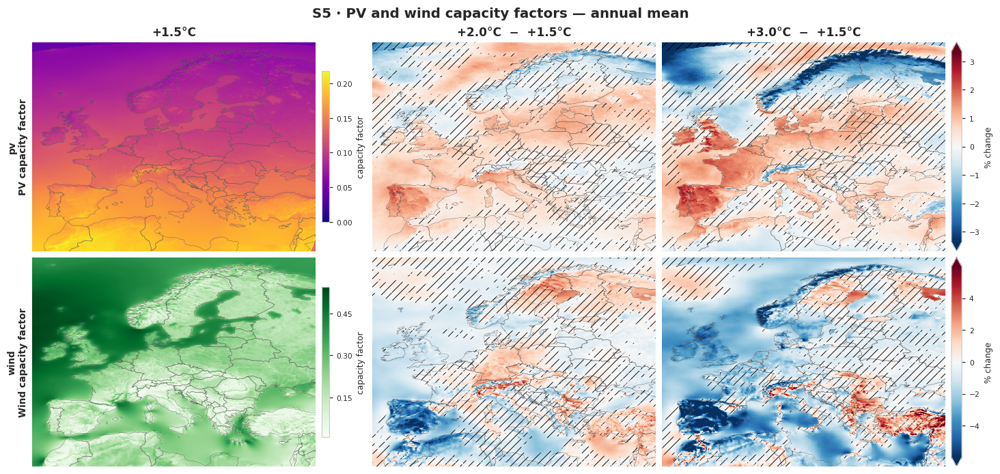

In [10]:
energy_annual = load_gwl_grids("")

# The pv/wind file predates the change_type convention, so declare it here rather than letting the
# plotting function gu|ess — it raises if the attribute is missing, which is the point.
for dataset in energy_annual.values():
    for variable, long_name in [("pv", "PV capacity factor"), ("wind", "Wind capacity factor")]:
        dataset[variable].attrs.update(change_type="percent", long_name=long_name)

fig = plot_climate_gwl_maps(energy_annual, ["pv", "wind"], countries, STYLE,
                            title="S5 · PV and wind capacity factors — annual mean")
fig.savefig(FIGS / "S5_capacity_factors_annual.png", dpi=200, bbox_inches="tight")

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


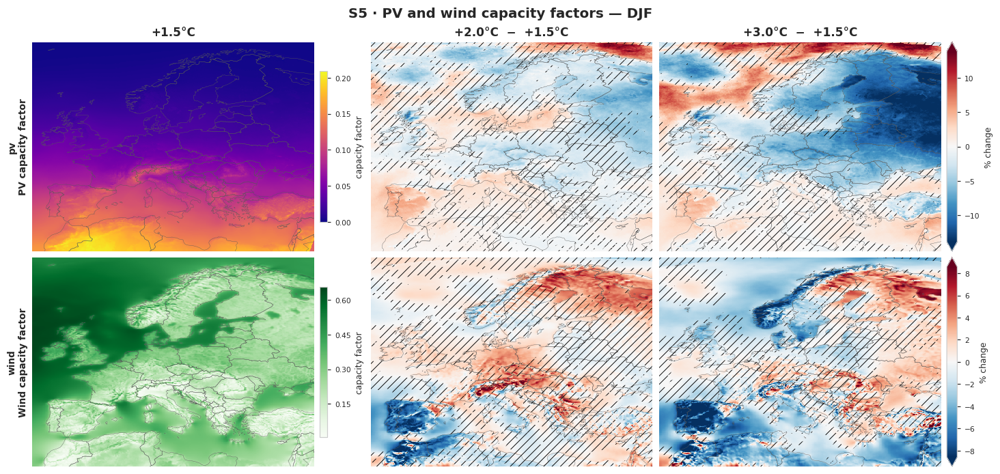

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


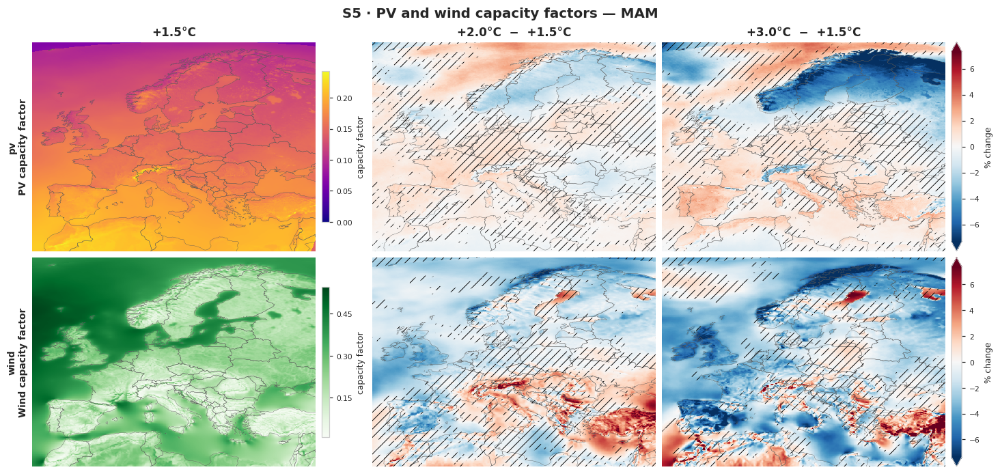

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


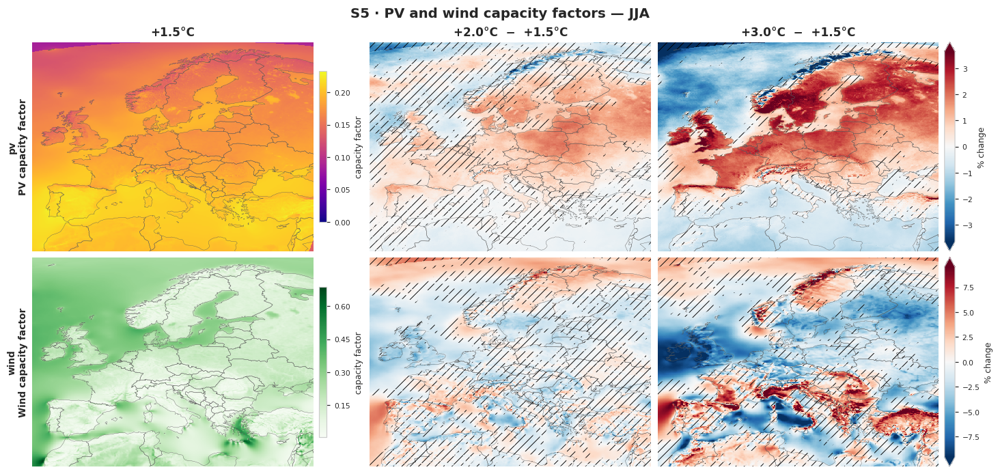

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


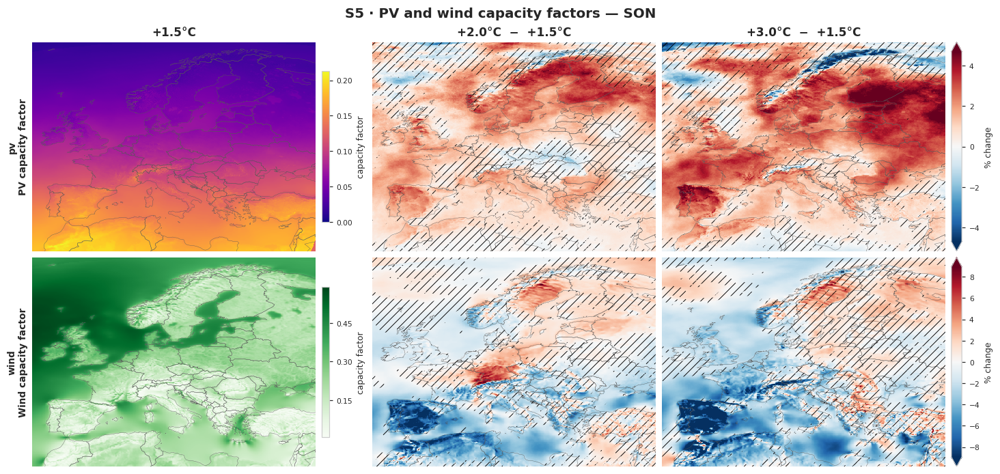

In [11]:
energy_seasonal = load_gwl_grids("", seasonal=True)
for dataset in energy_seasonal.values():
    for variable, long_name in [("pv", "PV capacity factor"), ("wind", "Wind capacity factor")]:
        dataset[variable].attrs.update(change_type="percent", long_name=long_name)

for season in SEASON_ORDER:
    fig = plot_climate_gwl_maps(energy_seasonal, ["pv", "wind"], countries, STYLE, season=season,
                                title="S5 · PV and wind capacity factors")
    fig.savefig(FIGS / f"S5_capacity_factors_{season}.png", dpi=200, bbox_inches="tight")
    plt.show()

## S6 · Hydro

Three different things that are easy to conflate:

* **run-of-river** — generation, driven directly by runoff;
* **reservoir inflow** — the *resource*, i.e. what the climate delivers;
* **reservoir dispatch** — the *decision*, i.e. what the optimiser chooses to release.

Only the inflow is a climate signal. The dispatch is an optimisation output and will happily
redistribute a constant inflow across the year, so it must never be read as a climate impact.
Countries with no reservoir fleet are greyed, not drawn as zero.

In [12]:
# Country-level hydro fields, per chain, per warming level, as a mean ANNUAL TOTAL in TWh/yr.
#
# The three fields come from two different places, and that is the point of the figure:
#   * run-of-river generation and reservoir DISPATCH are pipeline outputs -> components.nc
#   * the reservoir INFLOW is a climate input      -> the c2e cache
country_output_by_model = {
    m: xr.open_dataset(PATH_EXTREMES / "residual_load" / f"{m}_{CLIMATE_SCENARIO}" / RUN_TAG
                       / "components.nc")
    for m in models
}
c2e_hydro = {
    name: xr.open_dataarray(PATH_GWL / "c2e_cache" / f"c2e_{name}_{CLIMATE_SCENARIO}.nc")
    for name in ("hydro_inflow", "hydro_ror")
}

# Order: RoR, inflows, dispatch (resource → decision reads left-to-right within reservoirs).
HYDRO_FIELDS = [
    ("Run-of-river\ngeneration",
     lambda p: compute_country_gwl_field(country_output_by_model, period_defs, p,
                                         lambda d: d["gen_hydro_ror"])),
    ("Reservoir inflow\n(the resource)",
     lambda p: compute_c2e_gwl_field(c2e_hydro, period_defs, p, "hydro_inflow")),
    ("Reservoir dispatch\n(the decision)",
     lambda p: compute_country_gwl_field(country_output_by_model, period_defs, p,
                                         lambda d: d["reservoir_dispatch_gwh"])),
]

hydro_gwl = {
    label: {period: mask_structural_zeros(field(period)) for period in period_names}
    for label, field in HYDRO_FIELDS
}
for label, per_period in hydro_gwl.items():
    reference = per_period[REFERENCE]
    print(f"{label.replace(chr(10), ' '):<34} "
          f"{int(reference.count('country').max())} countries with a fleet, "
          f"{float(reference.sum('country').median()):.0f} TWh/yr")

Run-of-river generation            6 countries with a fleet, 130 TWh/yr
Reservoir inflow (the resource)    10 countries with a fleet, 272 TWh/yr
Reservoir dispatch (the decision)  10 countries with a fleet, 238 TWh/yr


/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


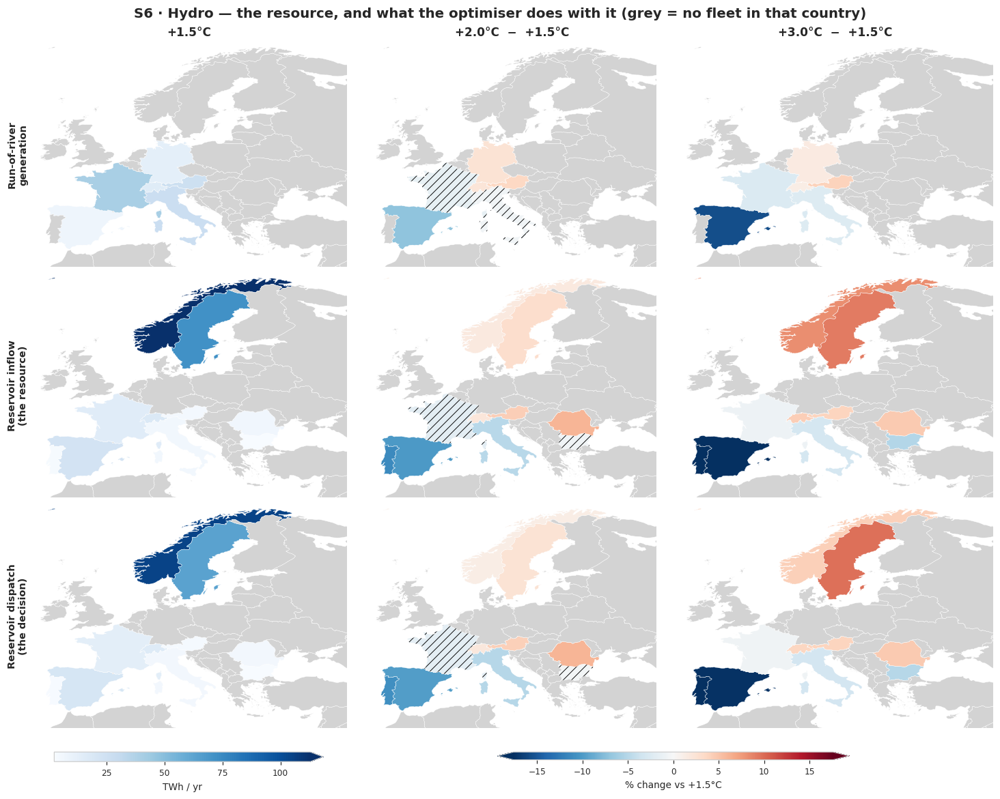

In [ ]:
# col 0 = absolute (Blues, one shared colorbar per row → equal aspect); cols 1-2 = % change vs +1.5,
# hatched where < 2/3 of the chains agree on the sign. Structural zeros (no fleet) stay grey.
fig = plot_country_gwl_maps(
    hydro_gwl, countries, STYLE, unit="TWh / yr",
    title="S6 · Hydro — the resource, and what the optimiser does with it "
          "(grey = no fleet in that country)")
fig.savefig(FIGS / "S6_hydro.png", dpi=200, bbox_inches="tight")

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


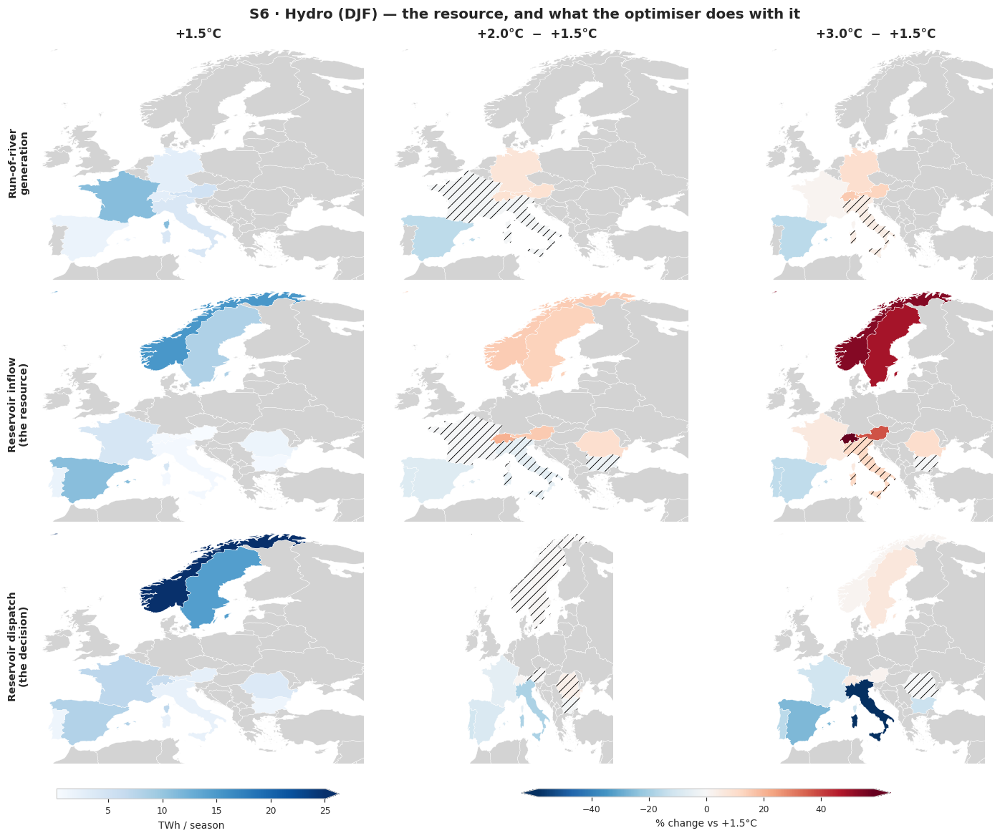

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


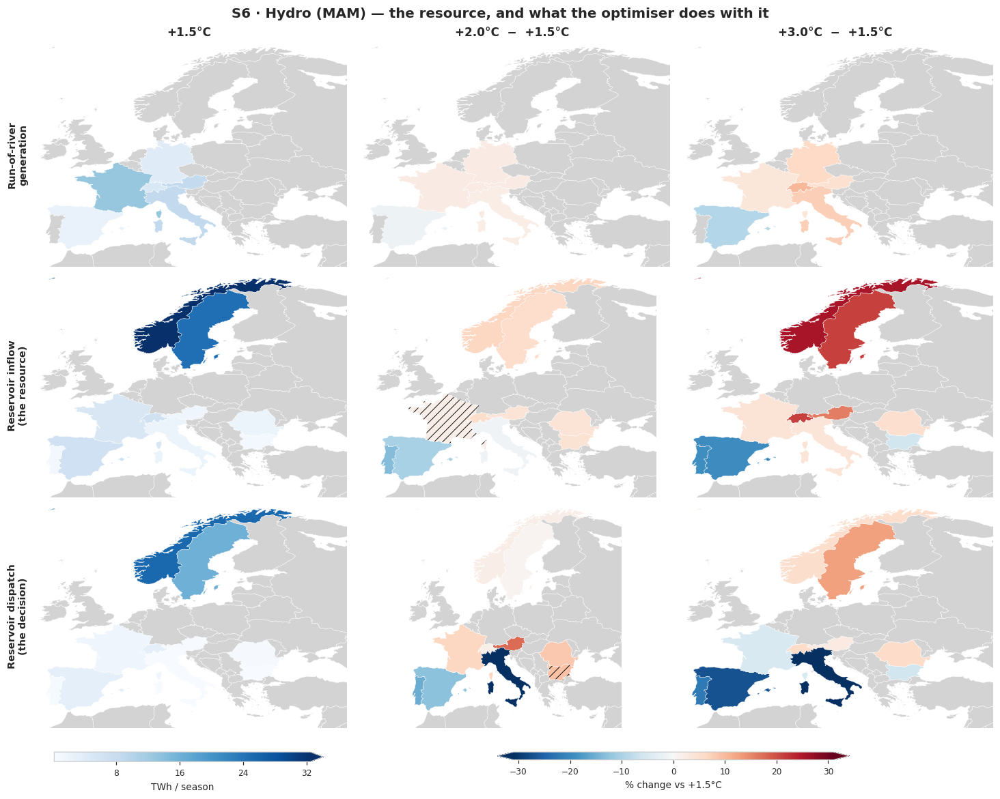

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


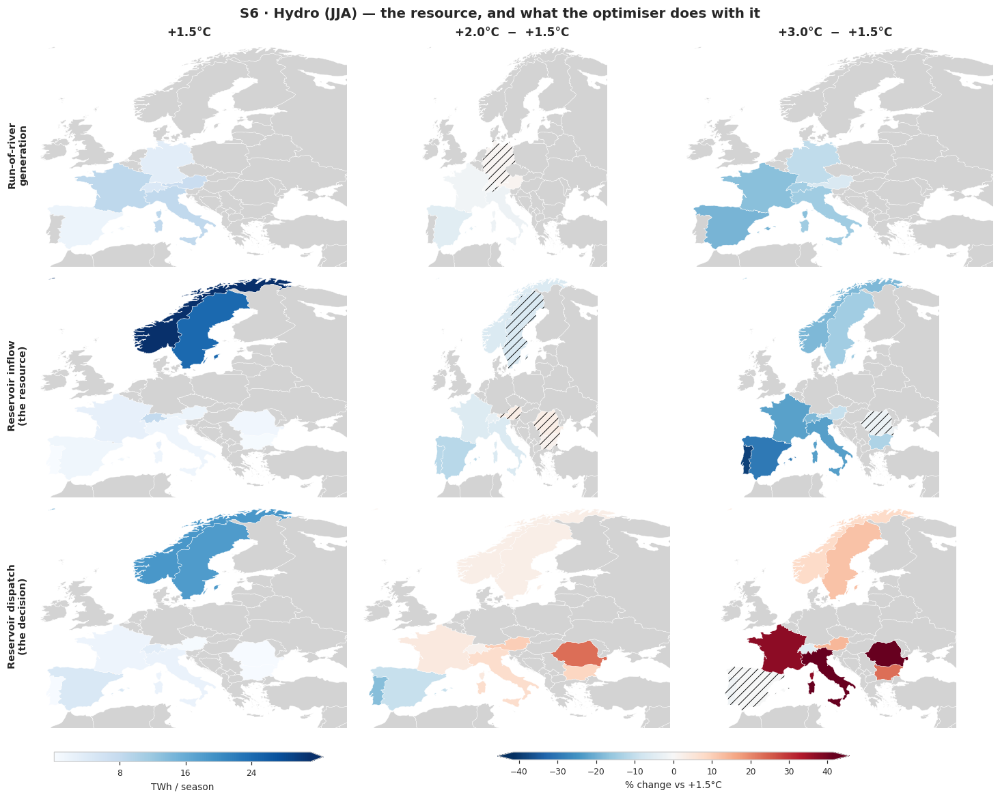

/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),
/home/yhaddad/CORDEX2Energy-Universe/CORDEX2Energy-analysis/cordex2energy_analysis/analysis.py:389: RuntimeWarning: Mean of empty slice
  lambda x: np.sum((np.sign(x) == np.sign(np.nanmean(x))) & ~np.isnan(x)),


: 

: 

In [17]:
# S6 (seasonal) — the same three hydro fields resolved per meteorological season. `months=` restricts
# each GWL-window total to the season, giving a mean SEASONAL total (TWh/season). This exposes the
# seasonal redistribution the reservoir performs (dispatch shifted toward winter demand) and the
# seasonality of runoff/inflow (snowmelt-driven) that the annual view averages away.
SEASON_MONTHS = {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}

hydro_field_fns = {
    "Run-of-river\ngeneration":
        lambda p, months: compute_country_gwl_field(country_output_by_model, period_defs, p,
                                                    lambda d: d["gen_hydro_ror"], months=months),
    "Reservoir inflow\n(the resource)":
        lambda p, months: compute_c2e_gwl_field(c2e_hydro, period_defs, p, "hydro_inflow",
                                                months=months),
    "Reservoir dispatch\n(the decision)":
        lambda p, months: compute_country_gwl_field(country_output_by_model, period_defs, p,
                                                    lambda d: d["reservoir_dispatch_gwh"],
                                                    months=months),
}

for season in SEASON_ORDER:
    hydro_gwl_season = {
        label: {p: mask_structural_zeros(fn(p, SEASON_MONTHS[season])) for p in period_names}
        for label, fn in hydro_field_fns.items()
    }
    fig = plot_country_gwl_maps(
        hydro_gwl_season, countries, STYLE, unit="TWh / season",
        title=f"S6 · Hydro ({season}) — the resource, and what the optimiser does with it")
    fig.savefig(FIGS / f"S6_hydro_{season}.png", dpi=200, bbox_inches="tight")
    plt.show()

## S7 · The TYNDP-2024 scenario

The build-out the paper assumes: **supply LOW / 2050**, **demand DE / 2050**.

There is no `2050_Best Estimate` column in the TYNDP supply file for solar, onshore wind or batteries
— only LOW and HIGH — so LOW/2050 is a genuine scenario choice, not a central estimate, and is labelled
as such. `paper_si_results.ipynb` (S20) re-runs the whole analysis under HIGH/2040 to show the
conclusions do not depend on it.

In [14]:
path_supply_excel = (PATH_EXTREMES / "tyndp"
                    / "20231103 - Final Supply Inputs for TYNDP 2024 Scenarios.xlsx")
capacity_column = f"{SUPPLY_YEAR}_{SUPPLY_SCENARIO}"

solar, wind_onshore, wind_offshore = load_tyndp_supply_capacities(path_supply_excel)

def to_iso2_gw(frame: pd.DataFrame) -> pd.Series:
    """TYNDP node codes ("AT00", "DKW1") -> ISO2, summed over nodes, MW -> GW."""
    nodes = frame[frame["Country"].astype(str).str.len() >= 2].copy()
    nodes["ISO2"] = nodes["Country"].astype(str).str[:2]
    return nodes.groupby("ISO2")[capacity_column].sum() / 1000.0

generation_gw = pd.DataFrame({
    "solar PV": to_iso2_gw(solar),
    "wind onshore": to_iso2_gw(wind_onshore),
    "wind offshore": to_iso2_gw(wind_offshore),
}).fillna(0.0)

battery_prosumer, battery_utility = load_tyndp_battery_capacities(
    path_supply_excel, scenario=SUPPLY_SCENARIO, year=SUPPLY_YEAR, return_separate=True)
battery_gwh = pd.DataFrame({
    "battery (prosumer)": battery_prosumer,
    "battery (utility)": battery_utility,
}).fillna(0.0)

# Keep only the countries the paper actually models.
modelled = sorted({c for members in REALTIME_BALANCING_ZONES.values() for c in members})
generation_gw = generation_gw.reindex(modelled).fillna(0.0)
battery_gwh = battery_gwh.reindex(modelled).fillna(0.0)

print(f"Generation (GW), {capacity_column}:")
print(generation_gw.sum().round(1).to_string())
print(f"\nBattery (GWh), {capacity_column}:")
print(battery_gwh.sum().round(1).to_string())

Generation (GW), 2050_LOW:
solar PV         1032.0
wind onshore      461.9
wind offshore     485.5

Battery (GWh), 2050_LOW:
battery (prosumer)    495.8
battery (utility)     545.2


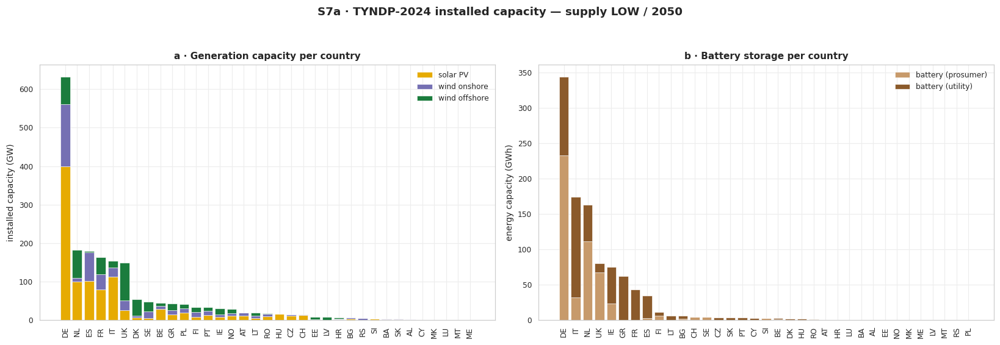

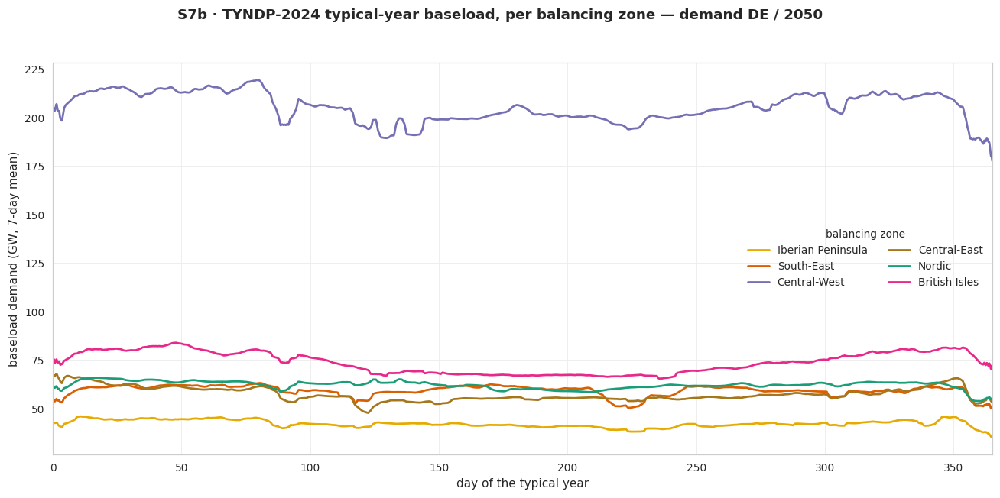

In [15]:
baseload = xr.open_dataset(
    PATH_EXTREMES / "tyndp" / "baseload" / f"baseload_{DEMAND_SCENARIO}_{DEMAND_YEAR}.nc")["baseload"]

# S7a — what is installed (generation and storage, separate panels: GW and GWh do not stack).
fig = plot_tyndp_capacity(generation_gw, battery_gwh,
                          scenario_label=f"supply {SUPPLY_SCENARIO} / {SUPPLY_YEAR}")
fig.savefig(FIGS / "S7a_tyndp_capacity.png", dpi=300, bbox_inches="tight")

# S7b — the typical-year baseload, per balancing zone (not aggregated), so the seasonal shape shows.
fig = plot_tyndp_baseload(baseload, REALTIME_BALANCING_ZONES, STYLE,
                          scenario_label=f"demand {DEMAND_SCENARIO} / {DEMAND_YEAR}")
fig.savefig(FIGS / "S7b_tyndp_baseload.png", dpi=300, bbox_inches="tight")

---

**Next:** `paper_si_results.ipynb` (S8–S21) — the residual load, the event statistics, and the
method defence (CERRA-vs-CORDEX calibration, threshold convention, scenario and flexibility
counterfactuals).